# Ending the ‘thermostat wars’: a Bayesian causal framework for thermal

comfort decision-making under occupant heterogeneity and uncertainty

Matteo Favero [ORCID profile for Matteo Favero](https://orcid.org/0000-0002-3853-2585)  
Marika Vellei [ORCID profile for Marika Vellei](https://orcid.org/0000-0001-5676-5991)  
Andrew Sonta [ORCID profile for Andrew Sonta](https://orcid.org/0000-0001-9021-0842)  
31 October, 2026

Human thermal responses are inherently variable and difficult to predict, yet thermal comfort assessments and building decisions often do not explicitly account for this heterogeneity and uncertainty when evaluating environmental interventions. This study investigates how Bayesian causal inference can improve thermal comfort assessment by quantifying intervention effects, their uncertainty, and heterogeneity in occupant responses. We applied the proposed framework to data from a historical laboratory thermal comfort experiment that contributed to the empirical foundation of Fanger’s predicted mean vote model. We defined causal estimands for hypothetical heating and cooling interventions and estimated their effects on thermal sensation while accounting for heterogeneity associated with biological sex, time of day, and exposure duration. The results showed that assumptions embedded in the predicted mean vote model, including fixed metabolic rates and steady-state representations of thermoregulation, contributed to discrepancies between predicted and observed thermal sensation. Thermal responses were not constant across occupants or over time: identical environmental interventions produced different effects by sex and exposure duration. To support engineering applications, we developed a utility-weighted dissatisfaction index to summarise predicted dissatisfaction while preserving uncertainty from the Bayesian model. This framework demonstrated that energy-saving temperature adjustments may have unequal consequences for different occupant groups. These findings highlight the importance of explicitly quantifying uncertainty and heterogeneity when evaluating thermal comfort interventions. Integrating probabilistic inference with decision-oriented performance metrics provides a transparent framework for building operations and design that better supports energy efficiency, occupant comfort, and thermal equity.

# Introduction

Humans respond differently to the same environmental conditions, yet many building engineering and design decisions rely on models that do not fully represent the variability and uncertainty in human responses \[@kim2018; @kramer2023\]. Standardised models provide a practical basis for scalable decision-making when individual characteristics are unknown or impractical to measure; however, their predictive value depends not only on estimating the average response but also on understanding the extent to which responses vary across individuals and groups. When systematic differences are not considered, models designed to represent typical conditions may provide incomplete information about how interventions affect different occupants, potentially leading to unequal outcomes in applications involving comfort, safety, or well-being \[@bogatu2023; @arakawamartins2022\]. The consequences of insufficiently representing biological variability are evident in other engineering fields. For example, vehicle safety systems were historically evaluated primarily using crash-test dummies representing the 50th-percentile male, whereas female dummies were commonly derived by scaling male anthropometric data rather than reflecting female biomechanics \[@carlsson2021; @inclusiv\]. Consequently, important sex-specific differences in injury mechanisms may not have been fully captured. This illustrates that including different groups in model development does not necessarily ensure that systematic differences between them are adequately represented in the resulting model.

Thermal comfort standards face a similar challenge. The predicted mean vote (PMV) model developed by Fanger remains the reference approach for assessing thermal comfort in international standards, including ISO 7730:2025 \[@internationalorganizationforstandardization\] and ASHRAE 55:2023 \[@americannationalstandardsinstituteamericansocietyofheatingrefrigeratingandair-conditioningengineers\]. PMV estimates mean thermal sensation based on environmental variables, including air temperature, mean radiant temperature, humidity and air velocity, together with assumptions regarding metabolic rate and clothing insulation \[@fanger1970\]. The model was developed from controlled climate-chamber experiments conducted in the mid-twentieth century and was intended to represent the average thermal response of the tested population \[@fanger1970; @nevins1966\]. Although these experiments included both male and female participants, the analytical approaches available at the time limited the ability to characterise heterogeneity in thermal responses. For example, ordinal thermal sensation votes were commonly analysed as continuous variables, repeated measurements were often not explicitly accounted for, and conclusions were frequently based on statistical significance rather than the magnitude and uncertainty of estimated effects \[@favero2023; @favero2024\]. These analytical choices may have limited the extent to which systematic differences between groups and over time could be characterised.

Reviews of thermal comfort research have identified substantial variability in human thermal responses associated with physiological, behavioural, contextual and psychological factors \[@rupp2015; @mishra2013; @schweiker2018\]. Sex is one factor that has received considerable attention. Sex differences in body morphology and composition, metabolic heat production, and thermoregulatory responses can influence thermal sensation under identical environmental conditions \[@karjalainen2012; @greenfield2023\]. Previous studies have generally reported that females are more likely to experience discomfort under cooler conditions, although the magnitude and practical relevance of sex-related differences vary across studies and environmental contexts \[@rupp2023; @nagashima2002; @kim2013; @cankar2000\]. Recent experimental and meta-analytic evidence further suggests that differences in thermal sensation and physiological responses are condition-dependent rather than fixed across environments \[@vellei2025\]. However, whether such differences require modifications to comfort models, or how they should be incorporated into practical building decisions, remains unresolved. Beyond sex-related differences, thermal responses may also vary over time. PMV assumes a steady-state heat balance and does not explicitly represent physiological adaptation or temporal changes during prolonged exposure \[@internationalorganizationforstandardization; @fanger1970\]. Additionally, the relationship between thermal sensation and perceived discomfort or dissatisfaction may vary across individuals and contexts, challenging the assumption that a single conversion applies universally \[@cheung2019; @schweiker2020\].

These limitations become increasingly relevant as energy and climate policies encourage wider indoor temperature ranges to reduce building energy demand. The International Energy Agency has identified strategies, such as reducing heating setpoints to approximately 19–20 °C and increasing cooling setpoints to approximately 24–25 °C, as important measures to reduce energy consumption \[@internationalenergyagency2021\]. However, if thermal responses differ systematically between occupant groups, interventions that do not account for this heterogeneity and the associated uncertainty may result in unequal comfort outcomes. Understanding such heterogeneity is therefore important for developing effective and equitable approaches to building operation and design.

Consequently, despite extensive research on thermal comfort, several important gaps remain. First, the intervention effect of interest is seldom defined explicitly before statistical modelling. Although many thermal comfort experiments involve controlled manipulation of environmental conditions, analyses typically focus on regression coefficients, predicted responses or hypothesis tests rather than clearly specifying the quantity that the analysis is intended to estimate. Explicitly defining causal estimands provides a transparent link between the scientific question, the intervention under consideration, the statistical analysis and the interpretation of the effects \[@rubin1974; @hernán2020; @lundberg2021; @kahan2024\]. Second, thermal comfort research findings are often interpreted primarily by whether *p*-values cross conventional significance thresholds. Such dichotomisation can obscure the magnitude and uncertainty of estimated effects and their potential implications for occupants and building operation. In particular, the absence of statistical significance does not necessarily imply the absence of a meaningful effect, just as statistical significance alone does not establish practical importance \[@wasserstein2016; @amrhein2019; @wasserstein2019\]. Although the statistical literature has long recognised the misinterpretation and dichotomisation of *p*-values \[@greenland2016; @greenland2017; @goodman2008\], these issues are particularly relevant when evaluating differences in thermal responses between occupant groups, environmental conditions, or exposure periods, where the practical importance of an estimated difference may not correspond directly to its statistical significance. Third, comfort-related outcomes are commonly derived from thermal sensation using predefined decision rules, such as classifying votes between –1 and 1 as comfortable and more extreme votes as indicating dissatisfaction. Although practical, these decision rules implicitly assume a universal relationship between thermal sensation and comfort-related outcomes. However, evidence suggests that this relationship varies across individuals and contexts \[@cheung2019; @schweiker2020\], indicating that a single mapping may not adequately represent all occupants. Finally, thermal comfort research has largely focused on statistical inference and model prediction, whereas engineering practice ultimately requires understanding the causal effects of environmental interventions to inform design and operational decisions, considering their expected consequences, uncertainty, costs and benefits.

In this study, we address these gaps through a Bayesian re-analysis of the laboratory experiment conducted by Nevins *et al.* \[@nevins1966\], which contributed to the empirical basis of the PMV model. We first define category-specific causal estimands for hypothetical interventions in air temperature and relative humidity, specifying the intervention effects of interest before developing the statistical model. We then estimate these intervention effects while characterising heterogeneity associated with biological sex, time of day and exposure duration. We further investigate how translating thermal sensation into discomfort-related decisions using Fanger’s conventional conversion and alternative utility-based approaches affects the resulting conclusions. By explicitly separating the estimand, statistical estimation, and decision-making, we show how uncertainty in predicted responses can propagate into practical comfort assessments.

# Methods

## Dataset

The dataset re-analysed in this study originates from the controlled climate-chamber experiments conducted by Nevins *et al*. in the mid-1960s \[@nevins1966\] and was extracted from a technical report by Rohles (Appendix D of \[@rohles1970\]). The experiments involved 720 college-age participants (360 males and 360 females; ages 18–23), tested in groups of 10, comprising 5 males and 5 females. Participants were exposed to one of 72 environmental conditions for 3.0 h, with each subject experiencing only a single condition. The experimental design combined nine dry-bulb air temperatures (18.9–27.8 °C, 1.1 °C increments) with eight relative humidity levels (15–85 %, 10 % increments). Environmental conditions were measured over two winter campaigns conducted during December 1963–January 1964 and December 1964–January 1965. Air velocity was maintained below 0.1 m/s, and the mean radiant temperature was controlled to equal the air temperature. Sessions were distributed equally between the afternoon (14:00–17:00) and evening (19:00–22:00) periods. Participants remained seated throughout the exposure and wore standardised clothing ensembles corresponding to approximately 0.6 clo. Thermal sensation votes were collected every 30 min after the first hour using a seven-point ASHRAE-type thermal sensation scale ranging from ‘cold’ to ‘hot’ with ‘comfortable’ as the central category.

## Causal estimand

The primary causal estimands were defined within the potential outcomes framework as the category-specific conditional average treatment effects (CATEs) of hypothetical joint interventions on air temperature and relative humidity. An intervention state, denoted by $a$, was defined as a specific combination of air temperature and relative humidity setpoints, while $a'$ denoted the corresponding baseline setpoint condition. The CATE for the thermal sensation category $k$ was defined as the difference between the probability of observing that category under intervention $a$ and the probability under the reference condition $a'$ conditional on the vector $X$, comprising biological sex, time of day and time since onset:

$$
{CATE}_{k}\left( a,a'|X \right) = \Pr{\left( Y^{a} = k\  \right|X}) - \Pr{\left( Y^{a'} = k\  \right|X})
$$ {#eq-CATE}

where $Y^{a}$ denotes the potential thermal sensation outcome under intervention $a$. The additive probability scale was selected because it provides a direct and clinically interpretable measure of intervention impact, expressed as percentage-point changes in the prevalence of each thermal sensation category. Unlike relative effect measures, such as risk ratios or odds ratios, the additive scale quantifies the absolute change in the probability of experiencing each thermal sensation category, allowing intervention effects to be interpreted directly as changes in category prevalence.

Sex- and time-of-day-specific heterogeneity in intervention responses was characterised by evaluating the CATE at predefined combinations of biological sex, time of day (afternoon or evening), and time since onset. Sex-specific contrasts were obtained by comparing CATEs between males and females while holding the temporal variables fixed, whereas time-of-day-specific contrasts were obtained by comparing afternoon and evening CATEs within each sex. All contrasts were evaluated at predefined time-since-onset values. Two joint environmental interventions were considered. The heating intervention was defined as a reduction in temperature setpoint from $a'$ = (25.0 °C, 35%rh) to $a$ = (23.5 °C, 35%rh). The cooling intervention was defined as an increase in temperature setpoint from $a'$ = (24.5 °C, 55%rh) to $a$ = (26.0 °C, 55%rh). Comfort-oriented temperature setpoints were determined using the PMV model, assuming airspeed (va) = 0.05 m/s, metabolic rate (M) = 1.1 met, clothing level (Icl) = 0.6 clo, and mean radiant temperature (tr) equal to air temperature (ta). Relative humidity was set to 35% and 55% to represent plausible indoor conditions associated with relatively dry winter and more humid summer environments, respectively. Under these assumptions, PMV = 0 was obtained at approximately 25.0 °C at 35% RH and 24.5 °C at 55% RH. The magnitude of each temperature perturbation was selected to ensure that the resulting thermal conditions remained within the conventionally acceptable comfort range (–0.5 ≤ PMV ≤ +0.5).

The causal interpretation of the estimated effects relies on the assumptions of *consistency*, *exchangeability*, *positivity* and *no interference* (the combination of consistency and no interference is also often referred to as the *stable unit treatment value assumption*, SUTVA). In the present study, we restricted the analysis to Nevins’ dataset to improve the plausibility of the causal assumptions. The study-specific rationale for each assumption is summarised in @tbl-causal-assumptions (a comprehensive text on causal inference discussing these assumptions can be found in Ref. \[@hernán2020\]).

In [ ]:
library(knitr)

table_1 <- read.csv("tables/table-main_01.csv")

kable(table_1, 
      col.names = c("Assumption", "", "Rationale in the present study")
)

  ----------------------------------------------------------------------------------------
  Assumption                                     Rationale in the present study
  ------------------ --------------------------- -----------------------------------------
  Consistency:       The observed outcome must   Consistency was plausible because the
                     correspond to the potential interventions were well defined, with the
                     outcome under the actual    assigned environmental setpoints defining
                     treatment value received.   the treatment. Clothing insulation,
                     This requires the treatment activity level (sedentary), exposure
                     to be well-defined, such    protocol, and exposure group size were
                     that each value or          kept constant.
                     combination of treatment    
                     values represents a clearly 
                     specified intervention.     

  Exchangeability:   The potential outcomes      Exchangeability was considered plausible
                     should be independent of    because the environmental conditions were
                     the assigned treatment,     experimentally assigned, reducing the
                     meaning that treatment      likelihood that participant
                     assignment should not be    characteristics or pre-existing thermal
                     related to the outcomes     responses systematically determined
                     that would have been        treatment assignment. The experiments
                     observed under other        were conducted during winter, providing a
                     possible treatment values.  relatively consistent context with
                                                 respect to seasonal acclimatisation.

  Positivity:        For all treatment values of Positivity was plausible because the
                     interest, there should be   intervention conditions in the analysis
                     adequate overlap in         fell within the range and combinations of
                     treatment assignment across air temperature and relative humidity
                     participants with relevant  represented in the experimental data,
                     characteristics, allowing   allowing the intervention contrasts of
                     the effects of the          interest to be estimated without
                     interventions to be         extrapolating beyond the observed data.
                     estimated.                  

  No interference:   The potential outcome for   The no-interference assumption was
                     one individual should not   considered plausible because participants
                     depend on the treatment     were exposed to the assigned
                     received by other           environmental conditions under a
                     individuals.                controlled protocol and were not
                                                 permitted to discuss their thermal
                                                 sensations during the experiments,
                                                 minimising the possibility that one
                                                 participant's treatment or reported
                                                 sensation influenced another
                                                 participant's outcome.
  ----------------------------------------------------------------------------------------


## Utility-weighted outcome index

To facilitate interpretation of the intervention effects, we constructed a general utility-weighted outcome index that summarises the predicted distribution over the seven outcome categories. This approach follows the general decision-theoretic principle of assigning utilities to possible outcomes and evaluating them through their expected utility \[@berger1985\]. Let $p_{k}\left( a|X \right)$ denote the posterior predicted probability of observing thermal sensation category $k$ under intervention $a$, conditional on the specified conditioning variables $X$. A utility-weighted index is defined as

$$
I\left( a|X \right) = \sum_{k}^{}{u(k)p_{k}\left( a|X \right)}
$$ {#eq-utily-weighted-index}

where $u(k)$ represents a set of predefined utility weights that reflect the relative desirability or severity of each outcome category. The causal effect on the index is given by

$$
\mathrm{\Delta}I(X) = I\left( a|X \right) - I\left( a'|X \right)
$$ {#eq-utily-weighted-index-diff}

which provides a single interpretable summary of changes in the full outcome distribution induced by the intervention.

This framework allows intervention effects on a multivariate categorical outcome to be expressed on a scalar utility scale while retaining the full category-specific probability structure as the primary estimand. In this study, we applied this general framework to define a Utility-Weighted Thermal Dissatisfaction Index (UWTDI), where the utility weights were chosen to reflect the dissatisfaction associated with each thermal sensation category. Three alternative utility formulations were considered: (i) the conventional binary Fanger weighting corresponding to the classical predicted percentage dissatisfied (PPD) definition, (ii) a binary Comfort weighting corresponding to satisfaction only at thermal neutrality, and (iii) a Symmetric graded weighting that assigned progressively greater dissatisfaction penalties with increasing deviation from thermal neutrality. The utility weights are reported in @tbl-utility-weights. These specifications represent different ways of relating thermal sensation to dissatisfaction, rather than competing estimates of a single underlying relationship.

In [ ]:
library(knitr)

table_2 <- read.csv("tables/table-main_02.csv")

kable(table_2, 
      col.names = c("TSV", "Fanger (binary)", "Comfort (binary)", "Symmetric (graded)")
)

  TSV     Fanger (binary)   Comfort (binary)   Symmetric (graded)
  ----- ----------------- ------------------ --------------------
  --3                   1                  1                 1.00
  --2                   1                  1                 0.75
  --1                   0                  1                 0.25
  0                     0                  0                 0.00
  1                     0                  1                 0.25
  2                     1                  1                 0.75
  3                     1                  1                 1.00


## Statistical analysis

Participant identifiers were unavailable in the original dataset, precluding the modelling of repeated measurements at the individual level. Consequently, the analysis was conducted using aggregated observations, with each observation represented by the counts of responses across the seven thermal sensation categories among five participants of the same biological sex for a given combination of experimental conditions. The response vector was assumed to follow a multinomial distribution:

$$
\mathbf{Y}_{i}\ \sim\ \text{Multinomial}\left( 5,\ \mathbf{p}_{i} \right)
$$ {#eq-likelihood}

where $\mathbf{Y}_{i}$ is the vector of observed counts across the seven thermal sensation categories for observation $i$, and $\mathbf{p}_{i} = \left\{ p_{i, - 3},\ \ldots,\ p_{i,3} \right\}$ is the corresponding vector of category probabilities.

Category probabilities were estimated using a Bayesian multilevel multinomial regression model with a baseline-category logit link, with ‘comfortable’ (TSV=0) specified as the reference category. For each non-reference category $k$,

$$
\log\left( \frac{p_{i,k}}{p_{i,0}} \right) = \eta_{ik}
$$ {#eq-baseline-category-logit}

where the linear predictor is

$$
\begin{aligned}
\eta_{ik} = {} & \alpha_{\text{condition}\lbrack i\rbrack,\ \text{sex}\lbrack i\rbrack,k} + \beta_{\text{condition}\lbrack i\rbrack,\text{t.onset}, k}\ \text{mo}\left( {t.onset}_{i} \right) + \beta_{\text{t.day},k}\ {t.day}_{i} \\
& + \beta_{\text{temp}, k}\ {temp}_{i} + \beta_{\text{hum},k}\ {hum}_{i} + \beta_{\text{temp.hum},k}\left( {temp}_{i}{hum}_{i} \right)
\end{aligned}
$$ {#eq-linear-predictor}

Here, $k$ indexes the TSV category, $\text{sex}\lbrack i\rbrack$ is an index variable identifying the biological sex of observation $i$, $\text{condition}\lbrack i\rbrack$ identifies the experimental condition, ${t.day}_{i}$ is the dummy variable for time of day (afternoon/evening), $\text{mo}\left( {t.onset}_{i} \right)$ denotes the monotonic effect of time since onset, ${temp}_{i}$ is centred air temperature, and ${hum}_{i}$ is centred relative humidity expressed in 5% units.

The condition-specific effects were decomposed into a constant (population-level) and mean-zero group-level effects:

$$
\begin{aligned}
\alpha_{\text{condition}[i],\text{sex}[i],k} &= {\overline{\alpha}}_{\text{sex}[i],k} + v_{\text{condition}[i],\text{sex}[i],k} \\[6pt]
\beta_{\text{condition}[i],\text{t.onset},k} &= {\overline{\beta}}_{\text{t.onset},k} + \upsilon_{\text{condition}[i],\text{t.onset},k}
\end{aligned}
$$

where $\overline{\alpha}$ and $\overline{\beta}$ represent the average effects across conditions, whereas $v$ represents the condition-specific deviations from these averages, allowing partial pooling across conditions. The varying effects were modelled jointly using a multivariate normal distribution, allowing correlations between condition-specific effects across thermal sensation categories. Posterior predicted probabilities under interventions $a$ and $a'$ were averaged across the observed experimental conditions to estimate sample-averaged category-specific CATEs, thereby accounting for the corresponding condition-specific varying effects. These estimates represent the expected intervention response across the analysed groups rather than for a specific experimental condition. Effect-modification contrasts and the utility-weighted thermal dissatisfaction index (UWTDI) were subsequently derived from these estimates.

To assess alternative model specifications, candidate models were compared using approximate leave-one-out cross-validation (LOO) with Pareto-smoothed importance sampling (PSIS). Candidate models retained the same hierarchical structure but differed in the inclusion of interaction terms involving air temperature, relative humidity and biological sex. Models were evaluated based on their estimated expected log predictive density (ELPD). Predictive performance was similar across candidate models; therefore, the model including only the air temperature–relative humidity interaction was selected for causal estimation. The complete set of candidate model specifications, prior distributions and additional computational details are provided in the Supplementary Information.

Data analysis was conducted in *R* \[@rcoreteam2025\] with the *RStudio* integrated development environment \[@positsoftware2026\]. Data preparation and wrangling were performed using the *tidyverse* \[@wickham2023\] and *data.table* \[@barrett2026\] packages. Statistical models were fitted using the *brms* package \[@bürkner2025\], with Bayesian posterior processing supported by *tidybayes* \[@kay2024\], and compared with the *loo* package \[@vehtari2026\]. We diagnosed model fits and Markov Chain Monte Carlo performance using $\widehat{R}$ and reported effective samples. All diagnostics indicate good model fit. Thermal comfort-related calculations were performed using the *comf* package \[@schweiker2024\], and data visualisation was supported by *ggplot2* (within tidyverse), *patchwork* \[@pedersen2025\] and *metR* \[@campitelli2025\]. Data and analysis code are available at GitHub [`https://github.com/mfavero8/thermostat-war`](https://github.com/mfavero8/thermostat-war), with a rendered, web-based version available at [`https://mfavero8.github.io/thermostat-war/`](https://mfavero8.github.io/thermostat-war/).

# Results

## PMV-based thermal sensation prediction performance

To characterise the dynamic nature of human thermal sensation, we mapped estimated thermal sensation votes (TSVs) across a continuous environmental envelope of air temperature of 18.5–28.5 °C and relative humidity levels of 15–85%. However, since a multinomial model estimates a vector of probabilities, one for each TSV category (i.e., seven in this case), we calculated the expected value of the predicted TSV distribution as follows:

$$
\text{E}(TSV) = \sum_{k = - 3}^{3}{k}\ {p_{k}}
$$ {#eq-expected-TSV}

where $p_{k}$ is the probability of observing TSV category $k$, $k \in \left\{ - 3,\ ...,\ 3 \right\}$. The resulting mean TSV provides a convenient descriptive summary, enabling direct comparison with Fanger’s predicted mean vote (PMV).




In [ ]:
library(knitr)

include_graphics("figures/figure-main_01.png")

@fig-expected-TSV illustrates the posterior predictive mean vote across a 3-hour exposure, stratified by biological sex, with time of day fixed to afternoon (corresponding evening analyses are shown in [Fig. S1](notebooks/supplementary-material-preview.html#fig-supp-expected-TSV-evening)). Comparing the empirical response surfaces with the overlaid PMV iso-lines reveals a nuanced relationship. Overall, the empirical regression boundaries (white lines) broadly follow the geometric orientation of the PMV contours (black lines) across much of the environmental domain. However, this agreement deteriorates at higher temperatures, where the empirical boundaries progressively diverge as relative humidity decreases. Whereas the PMV contours remain linear throughout this region, the empirical boundaries become increasingly curvilinear, exhibiting pronounced curvature at elevated temperatures. This behaviour indicates that the humidity dependence embedded within the PMV formulation fails to capture the nonlinear influence of humidity on perceived thermal sensation under warmer conditions. Both male and female cohorts exhibited systematic deviations from the PMV predictions. Assuming a met of 1.2, the resulting PMV neutrality contour (PMV = 0.0) consistently lay on the cooler side of the empirical response surfaces, indicating that participants reported cooler sensations than those predicted under the equivalent environmental conditions. This discrepancy was markedly sex-specific. For example, at a fixed relative humidity of 50%, PMV = 0 corresponds to an expected TSV of –0.59 and –0.71 for females after 1.0 and 3.0 h, respectively, compared with –0.19 and –0.34 for males. Reducing the metabolic rate assumed in the PMV calculation partially reconciled these differences. Using 1.1 met reduced the discrepancy for males, yielding expected TSV values of 0.08 after 1.0 h and –0.14 after 3.0 h, whereas the corresponding values for females were –0.31 and –0.45. A further reduction to 1.0 met brought the predicted TSV for females to neutrality after 1.0 h (–0.03), although a cool sensation remained after 3.0 h (–0.21). For males, the corresponding TSV values were 0.34 and 0.05. Overall, female participants exhibited a larger displacement from the PMV neutral baseline and consistently lower mean TSVs than males across corresponding temperature-humidity combinations. Furthermore, at lower temperatures, the female response surfaces displayed substantially larger regions associated with colder thermal sensations, represented by the expanded deep-blue regions across all exposure durations. @fig-expected-TSV also demonstrates a systematic temporal decline in predicted thermal sensation under steady-state environmental conditions. As exposure duration increased, the posterior mean TSV consistently decreased across identical temperature and humidity combinations. Consequently, cooler response regions expanded towards progressively higher temperatures, with the blue and green zones shifting horizontally across the environmental space. This consistent displacement indicates that thermal sensation progressively shifted towards cooler perceptions over time despite constant environmental conditions. Because these two-dimensional surfaces in @fig-expected-TSV summarise only the posterior expected values, they do not convey the associated statistical uncertainty. To address this limitation, we additionally present one-dimensional conditional cross-sections at fixed relative humidity levels (30%, 50%, and 70%) as continuous functions of air temperature in the Supplementary Information ([Fig. S2](notebooks/supplementary-material-preview.html#fig-supp-expected-TSV-temperature-afternoon) and [Fig. S3](notebooks/supplementary-material-preview.html#fig-supp-expected-TSV-temperature-evening)).

Although comparison with PMV predictions provides a descriptive assessment of thermal sensation across the environmental conditions studied, it does not directly quantify intervention-induced changes in the probability of individual thermal sensation categories. We therefore estimated conditional average treatment effects (CATEs) to formally quantify how simulated interventions redistributed TSV probabilities across environmental conditions and participant subgroups.

## Sex-specific heterogeneity in intervention responses

To evaluate the causal effects of temperature setpoint changes, we simulated counterfactual interventions representing two energy-saving strategies under heating and cooling operating modes. We first examined whether intervention effects were modified by biological sex, followed by analyses assessing modification by time of day. We conducted the primary sex-specific heterogeneity analysis with time of day fixed to the afternoon period; corresponding evening analyses are presented in the Supplementary Information ([Fig. S4](notebooks/supplementary-material-preview.html#fig-supp-sex-specific-prediction-evening) and [Fig. S5](notebooks/supplementary-material-preview.html#fig-supp-sex-specific-CATE-evening)).

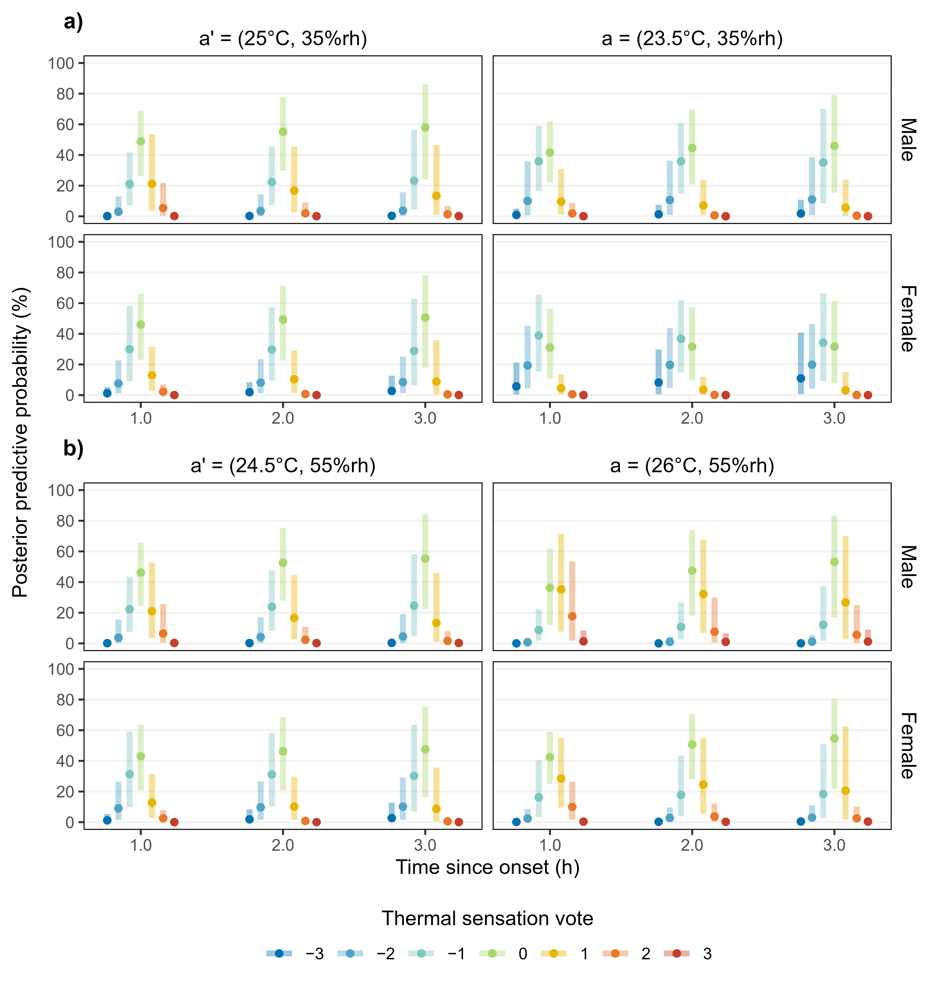

In [ ]:
library(knitr)

include_graphics("figures/figure-main_02.png")

@fig-sex-specific-prediction a presents the posterior predictive distributions of thermal sensation votes under heating conditions (25.0 °C and 23.5 °C at 35% relative humidity). Lowering the temperature from 25.0 °C to 23.5 °C shifted the distributions towards cooler sensation categories in both sexes. For example, among females after 3.0 h of exposure, the predicted probability of reporting ‘cold’ (TSV = –3) increased from approximately 3% at 25.0 °C to 11% at 23.5 °C, while the probability of a neutral sensation (TSV = 0) decreased from approximately 51% to 32%. Similar temperature-dependent shifts were observed in males, who consistently exhibited lower probabilities of cooler sensation categories, particularly ‘cold’ (TSV = –3), than females throughout the exposure period. The shift towards cooler sensations became more pronounced with increasing exposure duration, especially under the 23.5 °C condition. @fig-sex-specific-prediction b shows the corresponding posterior predictive distributions under cooling conditions (24.5 °C and 26.0 °C at 55% relative humidity). Increasing the temperature from 24.5 °C to 26.0 °C shifted the distributions towards neutral and warmer sensation categories. For instance, among females at 3.0 h, the predicted probability of being ‘comfortable’ (TSV = 0) increased from approximately 43% to 55%, whereas the probability of reporting ‘cool’ (TSV = –2) decreased from approximately 10% to 3%. Males exhibited a different temperature-dependent response, with consistently lower probabilities of being ‘comfortable’ and substantially higher probabilities of reporting ‘slightly warm’ (TSV = 1) and ‘warm’ (TSV = 2) than females across the exposure period. Across both environmental conditions, longer exposure durations were associated with a gradual shift towards lower thermal sensation votes, consistent with the temporal trends observed in @fig-expected-TSV. Although the predicted distributions displayed clear systematic patterns, the corresponding credible intervals were relatively wide because the marginal (sample-averaged) predictions integrate over the varying effects for experimental groups, thereby incorporating between-group variability beyond that explained by the constant effects. To quantify these temperature- and humidity-induced changes, we estimated conditional average treatment effects (CATEs) on the risk-difference scale for each TSV category. Differences in CATEs between males and females were subsequently evaluated to assess sex-specific effect modification over time.

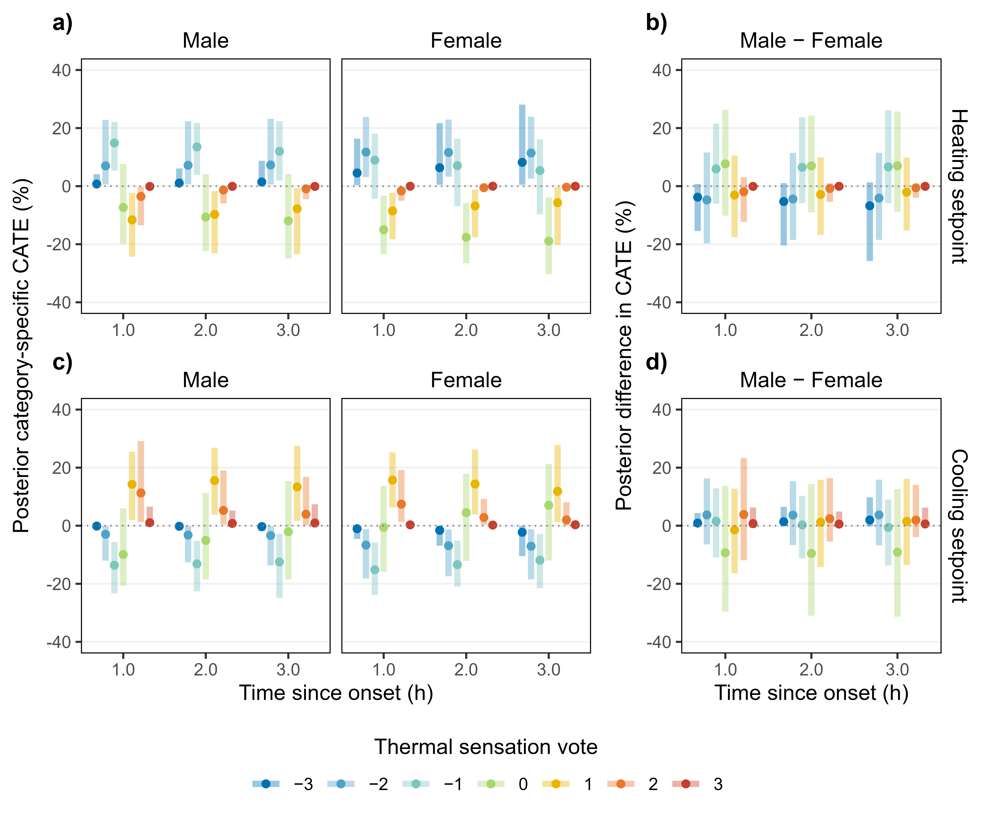

In [ ]:
library(knitr)

include_graphics("figures/figure-main_03.png")

@fig-sex-specific-CATE presents the CATEs of the temperature interventions on the probability of each TSV category. Under the heating intervention (25.0 °C to 23.5 °C at 35% relative humidity; @fig-sex-specific-CATE a), reducing the temperature redistributed probability from neutral towards colder sensation categories in both sexes. Among males, the intervention increased the probability of ‘cold’ (TSV = –3) by 0.7–1.4 percentage points on average and decreased the probability of ‘comfortable’ (TSV = 0) by approximately 7–12 percentage points across the exposure period. In females, the corresponding increase in the probability of TSV = –3 was larger (4.5–8.2 percentage points on average), accompanied by reductions of approximately 15–19 percentage points in the probability of ‘comfortable’. Although the magnitude of the effects varied only modestly across the 3-h exposure period, the intervention consistently shifted probability towards colder thermal sensation categories, with larger effects observed in females. Sex-specific differences (i.e., effect modification) in the heating intervention are shown in @fig-sex-specific-CATE b. Compared with females, males exhibited a smaller increase in the probability of the coldest sensation (TSV = –3 and –2; approximately 4–7 percentage points lower) but a larger increase in the probability of TSV = –1 (approximately 6–7 percentage points higher). While most 95% credible intervals overlapped zero, the posterior distributions favoured stronger responses among females for the coldest sensation category ($\Pr\left( \mathrm{\Delta}{CATE}_{k=-3,M - F} < 0\ \right|\text{afternoon,\ 3h}) = 94.3\%$; [Table S8](notebooks/notebooks/supplementary-material-preview.html#tbl-supp-effect-modification-heating-direction-sex)), whereas males showed correspondingly larger intervention effects for TSV = –1. Under the cooling intervention (24.5 °C to 26.0 °C at 55% relative humidity; @fig-sex-specific-CATE c), increasing the temperature shifted the probability distribution towards neutral and warmer sensation categories. Among males, the intervention increased the probability of reporting ‘slightly warm’ (TSV = 1) by approximately 13–14 percentage points, while reducing the probability of being ‘comfortable’ (TSV = 0). Females exhibited a different response pattern: the probability of being ‘comfortable’ decreased only minimally after 1.0 h (–0.6%), but this trend reversed with prolonged exposure, resulting in an increase of approximately 7 percentage points after 3.0 h. Compared with the heating intervention, the CATEs under cooling showed a clear reduction in the probabilities of colder sensation categories (TSV = –3 and –2) and an increase in warmer sensation categories (TSV = 1 and 2) for both sexes. For these categories, the estimated male–female differences were consistently smaller under cooling than under heating. In contrast, the effects on the ‘comfortable’ category were larger but accompanied by greater posterior uncertainty (@fig-sex-specific-CATE d).

## Time-of-day heterogeneity in intervention responses

Using the same analytical framework described for sex-specific heterogeneity, we next evaluated whether intervention-induced changes in thermal sensation probabilities varied according to time of day (predicted thermal sensation probabilities are shown in [Fig. S6](notebooks/supplementary-material-preview.html#fig-supp-day-specific-prediction-male)).

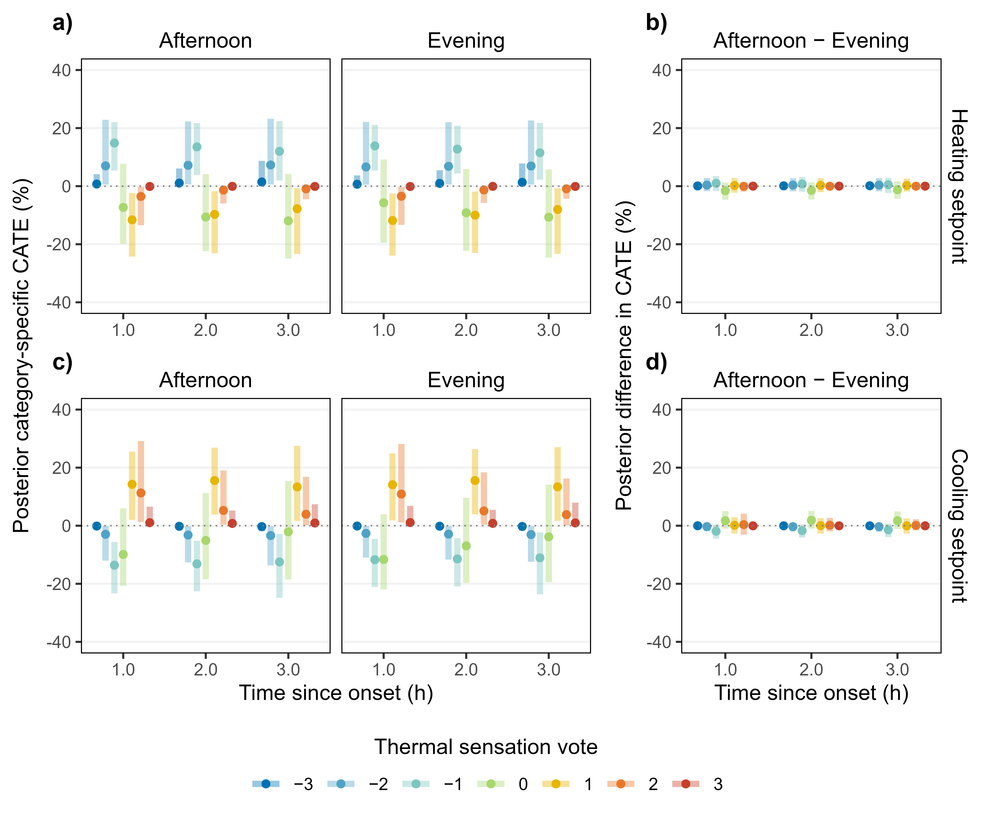

In [ ]:
library(knitr)

include_graphics("figures/figure-main_04.png")

The CATE estimates for the afternoon and evening periods were very similar for both the heating and cooling interventions (@fig-day-specific-CATE a and c). Accordingly, effect modification by time of day was less pronounced than effect modification by sex for both interventions. Differences between the afternoon and evening periods were generally small (with average differences of less than 2 percentage points in absolute value; @fig-day-specific-CATE b and d), with narrower posterior uncertainty suggesting greater consistency in intervention effects across time periods. The analyses presented in @fig-day-specific-CATE were conducted with biological sex fixed to male; the corresponding analyses for females are shown in the Supplementary Information ([Fig. S7](notebooks/supplementary-material-preview.html#fig-supp-day-specific-prediction-female) and [Fig. S8](notebooks/supplementary-material-preview.html#fig-supp-day-specific-CATE-female)).

## Decision-oriented thermal comfort evaluation

Because TSV categories were modelled using a multinomial framework, category-specific probabilities are inherently interdependent, such that increases in the probability of one category necessarily correspond to decreases in the probabilities of the others. Consequently, intervention effects should be interpreted as a redistribution of probability mass across the thermal sensation spectrum rather than independent changes in individual outcome categories. Although category-specific CATEs provide detailed insight into these redistribution dynamics, interpretation across multiple TSV categories can become fragmented when evaluating the overall desirability of alternative intervention strategies. Given the smaller magnitude of time-of-day effect modification compared with sex-related effect modification, we focus on sex-related heterogeneity in the following analyses. All estimates are calculated by fixing the time of day to afternoon.




In [ ]:
library(knitr)

include_graphics("figures/figure-main_05.png")

To enable integrated evaluation of thermal responses, we summarised posterior TSV distributions using a utility-weighted thermal dissatisfaction index (UWTDI), allowing intervention effects to be expressed on a decision-relevant scale. Posterior UWTDI response curves under three alternative utility specifications (@tbl-utility-weights) are shown in @fig-UWTDI-temperature. Direct comparison with the PPD lines is most meaningful under the Fanger weighting scheme (@fig-UWTDI-temperature, top). At lower temperatures, the PPD calculated assuming a met of 1.2 consistently underestimates the posterior expected UWTDI at both relative humidity levels. This discrepancy increased with exposure duration and was systematically larger for females than for males. However, if we assume a metabolic rate of 1.0 met for females and 1.1 met for males, the discrepancy diminishes. At these lower temperatures, relative humidity had little apparent influence on the agreement between the PPD and the posterior expected UWTDI. In contrast, at higher temperatures, the agreement depended on relative humidity, indicating that humidity effects became evident only under warmer conditions. Using different metabolic rates to calculate the PPD had little impact compared with lower temperatures. At 30% relative humidity, the PPD overestimated the posterior expected UWTDI, with the discrepancy progressively increasing over the 3-hour exposure. In contrast, at 70% relative humidity, the PPD underestimated the posterior expectation, although this difference diminished over time. At 3.0 hours, the PPD calculated with 1.0 met and 1.1 met closely followed the posterior expected UWTDI for females and males, respectively. Across all conditions, the 95% CrIs showed substantial overlap between the male and female estimates, reflecting considerable uncertainty in the posterior expectations, particularly for males. Compared to the Fanger weighting scheme, under the Comfort weighting scheme (@fig-UWTDI-temperature, middle) resulted in a substantially higher minimum posterior expected UWTDI, increasing to approximately 60% and 40% after 1.0 and 3.0 hours, respectively. This lower bound is determined by the assigned utility weights; assigning non-zero utilities to the ‘slightly cool’ (TSV = −1) and ‘slightly warm’ (TSV = +1) categories increases the theoretical minimum expected dissatisfaction. Transitioning from the binary weights of the Fanger and Comfort scheme to the Symmetric graded weighting architectures produced smoother response curves and overall narrower posterior uncertainty intervals (@fig-UWTDI-temperature bottom). Here, the posterior expected UWTDI estimates are more closely aligned with the PPD predictions (black lines), although the slope at lower air temperatures appears to differ. In particular, the posterior expected UWTDI for males (orange lines) andfemales (violet lines) has a higher minimum than the 6% minimum predicted by PPD. For example, after 1.0 hour, the minimum posterior expected UWTDI is approximately 20%.

Having established these utility-dependent thermal comfort curves, we next examined how the simulated heating and cooling interventions altered expected comfort. For clarity, @fig-UWTDI-heatmap presents results for the Fanger weighting scheme only; corresponding analyses using the alternative weighting schemes are provided in the Supplementary Information ([Fig. S10](notebooks/supplementary-material-preview.html#fig-UWTDI-heatmap-Fanger-evening) – [Fig. S20](notebooks/supplementary-material-preview.html#fig-UWTDI-heatmap-Symmetric-female)). Intervention trajectories were represented as directed transitions across posterior expected UWTDI landscapes (red and blue arrows).

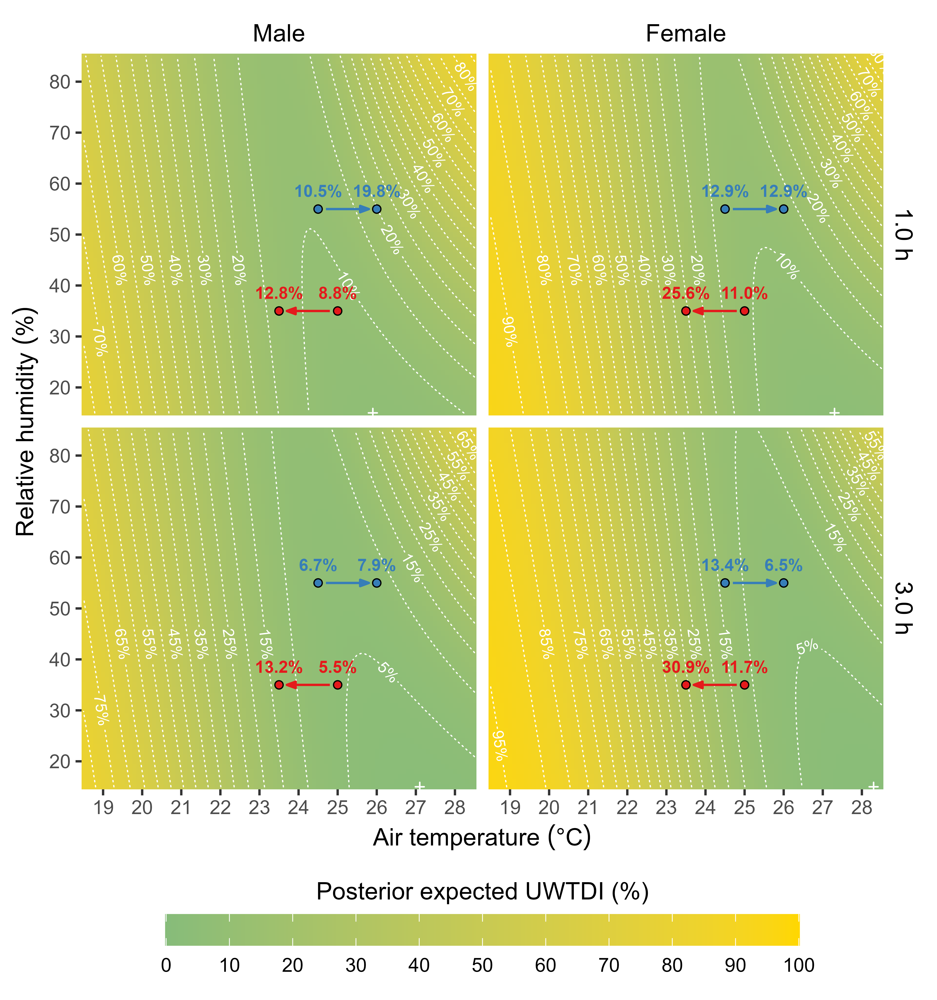

In [ ]:
library(knitr)

include_graphics("figures/figure-main_06.png")

Reducing the heating setpoint from 25.0 °C to 23.5 °C under 35% relative humidity (red arrows) markedly increased the posterior expected UWTDI in both sexes. Females exhibited substantially greater expected dissatisfaction than males throughout the exposure period, reaching 30.9% after 3.0 hours compared with 13.2% for males. Conversely, increasing the cooling setpoint from 24.5 °C to 26.0 °C at 55% relative humidity (blue arrows) reduced the posterior expected UWTDI for females but increased it for males. Females exhibited no reduction in expected dissatisfaction after 1.0 h (12.9%), although a reduction became evident after 3.0 h. In contrast, males showed an initial increase in expected dissatisfaction after 1.0 h (from 10.5% to 19.8%), but this increase diminished with longer exposure.

However, the two-dimensional landscapes in @fig-UWTDI-heatmap represent only the posterior expectation of UWTDI and therefore do not convey the uncertainty associated with these estimates. To characterise this uncertainty, @fig-UWTDI-distribution presents the full posterior distributions of UWTDI under the baseline and intervention setpoints, together with the posterior distributions of the intervention contrasts ($a - a'$). For clarity, this figure presents results for the Fanger weighting scheme only; corresponding analyses using the alternative weighting schemes are provided in the Supplementary Information ([Fig. S21](notebooks/supplementary-material-preview.html#fig-UWTDI-distribution-Fanger-evening) – [Fig. S25](notebooks/supplementary-material-preview.html#fig-UWTDI-distribution-Symmetric-evening)).

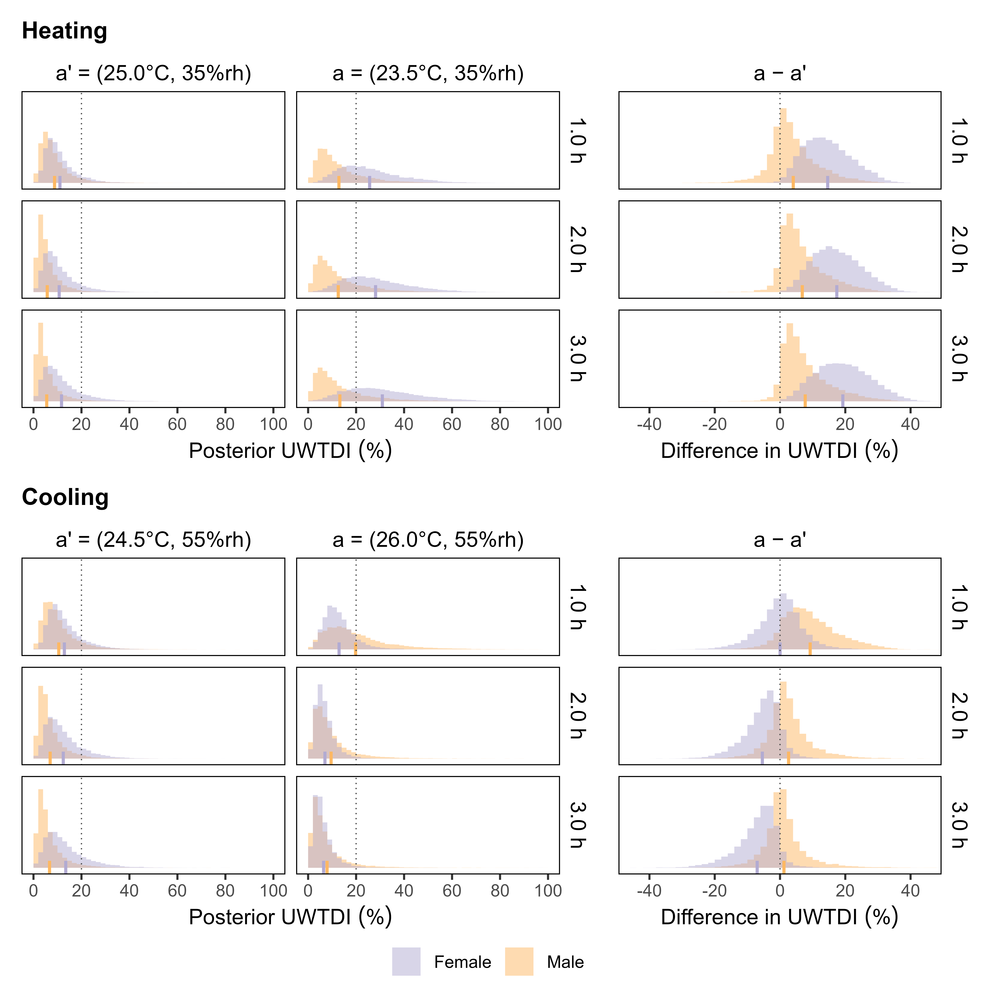

In [ ]:
library(knitr)

include_graphics("figures/figure-main_07.png")

Under the heating intervention, the posterior distributions shifted toward higher UWTDI values in both sexes, increasing the posterior probability of exceeding the 20% reference threshold. However, the magnitude of this shift differed substantially between females and males. In females, the posterior distributions of the intervention contrast ($a - a'$) were concentrated almost entirely above zero, with mean increases in UWTDI of 14.6% after 1.0 h and 19.2% after 3.0 h ([Table S16](notebooks/supplementary-material-preview.html#tbl-supp-UWTDI-distribution-Fanger-heating-direction)). Accordingly, the posterior probability that the intervention increased UWTDI, $\Pr(\mathrm{\Delta}UWTDI > 0\ | \text{ female, afternoon})$, exceeded 99.5% at all exposure durations ([Table S16](notebooks/supplementary-material-preview.html#tbl-supp-UWTDI-distribution-Fanger-heating-direction)). Males exhibited the same overall pattern but with markedly smaller increases. The posterior means of the intervention contrast were 4.4% after 1.0 h and 7.7% after 3.0 h ([Table S16](notebooks/supplementary-material-preview.html#tbl-supp-UWTDI-distribution-Fanger-heating-direction)), with the corresponding posterior probability of an increase in UWTDI, $\Pr(\mathrm{\Delta}UWTDI > 0\ | \text{ male, afternoon})$, rising from 72.8% after 1.0 h to 94.2% after 3.0 h ([Table S16](notebooks/supplementary-material-preview.html#tbl-supp-UWTDI-distribution-Fanger-heating-direction)). In contrast, the cooling intervention elicited distinct temporal responses in females and males. In females, the posterior distribution of the intervention contrast ($a - a'$) assigned substantial probability to both positive and negative values after 1.0 h, indicating considerable uncertainty regarding the direction of the intervention effect at this early time point. By 2.0 and 3.0 h, the posterior mass progressively shifted below zero, providing increasing evidence that the cooling intervention reduced UWTDI. This temporal pattern was reflected in the posterior probability of the intervention reducing UWTDI, $\Pr(\mathrm{\Delta}UWTDI < 0\ | \text{ female, afternoon})$, which increased from 47.5% after 1.0 h to 92.5% after 3.0 h ([Table S18](notebooks/supplementary-material-preview.html#tbl-supp-UWTDI-distribution-Fanger-cooling-direction)). In males, the response followed the opposite trajectory. After 1.0 h, the posterior distribution of the intervention contrast was concentrated almost entirely above zero, with a mean increase in UWTDI of 9.2% and a 90.2% posterior probability that the intervention increased UWTDI ($\Pr(\mathrm{\Delta}UWTDI > 0\ | \text{male, afternoon}$, [Table S18](notebooks/supplementary-material-preview.html#tbl-supp-UWTDI-distribution-Fanger-cooling-direction)). With longer exposure, however, the posterior distribution shifted toward zero, indicating increasing uncertainty regarding the direction of the intervention effect. By 3.0 h, the posterior probability that the intervention increased UWTDI had declined to 55.5% ([Table S18](notebooks/supplementary-material-preview.html#tbl-supp-UWTDI-distribution-Fanger-cooling-direction)), suggesting limited evidence for a directional effect.

# Discussion

We present a Bayesian causal re-analysis of the laboratory experiment conducted by Nevins *et al*. in the mid-1960s \[@nevins1966\], which formed part of the empirical basis for the development of the PMV/PPD model \[@fanger1970\]. Beyond providing an empirical benchmark for evaluating the PMV, the present study demonstrates how causal inference can be used to quantify the effects of environmental interventions on thermal sensation while explicitly characterising uncertainty. More importantly, it illustrates how probabilistic inference can be translated into decision-making through a utility-based dissatisfaction index. This distinction is important because statistical inference addresses what can be learned from data, whereas (engineering) decisions require selecting actions according to their expected consequences.

Our analysis indicates that several assumptions embedded within the PMV may contribute to systematic discrepancies between predicted and observed thermal sensation. Using the standard metabolic rate of 1.2 met, recommended for sedentary activity in ISO 7730:2025 \[@internationalorganizationforstandardization\], underestimated thermal neutrality, particularly for females and during prolonged exposure (@fig-expected-TSV). Although reducing the assumed metabolic rate improved agreement with observations, no single value reconciled predictions across sexes and exposure durations. These findings are consistent with recent studies reporting that measured metabolic rates during sedentary activities are frequently lower than the standard values adopted in thermal comfort standards \[@sabit2026; @gao2023; @zhai2018; @nomoto2021\] and that females generally exhibit lower metabolic heat production than males under comparable conditions \[@gao2023; @nomoto2021\]. Nevertheless, our findings do not support the conclusion that the observed discrepancies can be resolved simply by assigning different fixed metabolic rates to different subgroups. Indeed, the observed discrepancies are unlikely to arise solely from assumptions regarding metabolic rate. Various PMV extensions have been proposed to address these deviations by applying correction factors \[@humphreys2002; @olefanger2002; @yao2009\]. While these modifications can improve empirical agreement under specific conditions, they generally adjust PMV outputs rather than address the underlying physiological assumptions of the heat-balance model. Important limitations include simplified representations of thermoregulatory responses, particularly evaporative heat loss, where sweating is primarily linked to metabolic rate and assumed to be zero at 1.0 met, as well as the steady-state assumption that does not account for temporal changes in physiological responses during prolonged exposure. Omidvar and Kim \[@omidvar2020\] proposed a modified PMV formulation incorporating a new evaporative heat-loss equation into the original model and demonstrated improved predictions of thermal sensation across independent experimental datasets. Similarly, PMV’s inability to account for dynamic physiological adaptation may contribute to deviations observed during extended exposures. Consistent with these limitations, the estimated relationship between thermal sensation, temperature and relative humidity deviated from the approximately parallel comfort contours predicted by PMV, particularly at higher temperatures (@fig-expected-TSV). A gradual decline in mean TSV over the 3.0 h exposure was also reported by Fanger (Fig. 20, p. 75 of \[@fanger1970\]) using an experimental protocol closely resembling that of Nevins *et al*. \[@nevins1966\]. Fanger attributed this temporal shift to participants entering the climate chamber with a slightly elevated activity level; however, physiological adaptation or changes in metabolic heat production during prolonged exposure cannot be excluded, as metabolic rate was not directly measured. Together, these findings suggest that discrepancies between PMV predictions and observed thermal sensation may reflect limitations in the model’s representation of both physiological heat balance and its temporal dynamics, rather than inaccuracies in assumed metabolic rate alone.

The interpretation of Fanger’s experimental findings also requires consideration of his analytical approach. Although Fanger observed a temporal decline in TSV, the neutral temperatures derived from his analysis did not show statistically significant differences by sex, age group, or time of day. This apparent difference from the present findings may partly reflect differences in the analytical approach: rather than deriving neutral temperature directly from the observed relationships between TSV, temperature, and relative humidity, Fanger used the PMV comfort equation to transform experimental conditions into equivalent temperatures at a reference relative humidity. Consequently, the reported neutral temperatures were conditional upon the assumptions of the PMV heat-balance model, including its representation of evaporative heat loss and the interaction between humidity and thermoregulation. Because the original observations are no longer available, the extent to which this transformation influenced the reported conclusions cannot be determined. Additionally, differences in how the central thermal sensation category is defined may contribute to discrepancies when comparing results with Fanger’s experiments, as his original studies used ‘neutral’ rather than ‘comfortable’ as the midpoint category.

A principal advantage of Nevin’s study is the availability of a large controlled experimental dataset covering a broad range of temperature and relative humidity conditions. The randomised exposure design provides a strong basis for estimating causal effects of environmental conditions on thermal sensation, while the extensive sampling enables assessment of heterogeneity in thermal responses across sexes and exposure durations. Rather than estimating only the expected thermal sensation vote, the model quantifies how environmental interventions redistribute the probabilities across all seven thermal sensation categories. Importantly, the estimated causal effects were modified by sex and time of day and varied with exposure duration, indicating that thermal responses to identical environmental conditions are not fully invariant across participant groups or over time. However, the magnitude and precision of these effect modifications varied by factor. Sex-related differences were observed, although these estimates were accompanied by greater uncertainty, whereas the effects of time of day were comparatively smaller and more certain. This uncertainty reflects the marginal nature of the predictions, which integrate over the varying effects associated with experimental groups and therefore incorporate between-group variability. The larger effects observed between males and females are consistent with established physiological differences in body composition and morphology, metabolic heat production and thermoregulatory responses \[@greenfield2023; @vellei2025; @notley2017\]. By contrast, the higher thermal sensation observed in the evening compared with the afternoon, although small in magnitude, is consistent with circadian modulation of thermoregulatory processes. As the body prepares for sleep, core body temperature declines while skin temperature increases owing to enhanced peripheral heat dissipation, increasing sensitivity to environmental warmth under otherwise identical physical conditions \[@edwards2025; @waterhouse2007; @vellei2023\]. Furthermore, the gradual evolution of thermal sensation during the three-hour exposure suggests that steady-state models do not fully capture the temporal evolution of human thermal responses. Even under constant environmental conditions, thermal sensation continued to change over time, consistent with physiological adaptation or other time-dependent thermoregulatory processes.

Our findings contribute to the literature on heterogeneity in thermal comfort by showing that thermal responses vary across biological sex and over time, including differences associated with time of day and exposure duration. These findings are broadly consistent with previous studies reporting sex-related and temporal differences in thermal responses \[@greenfield2023; @vellei2025; @notley2017; @edwards2025; @waterhouse2007; @vellei2023\], while also highlighting that the magnitude and direction of these effects may depend on the conditions and exposure periods considered. Rather than interpreting heterogeneity solely according to whether *p*-values cross conventional significance thresholds, Bayesian inference provides a direct representation of uncertainty through posterior distributions, allowing the magnitude and probability of plausible effects to be evaluated and interpreted in relation to their potential consequences for thermal comfort. This distinction is important because statistical evidence for a difference does not by itself establish its practical importance, while an uncertain estimate does not necessarily imply that an effect is negligible.

More fundamentally, statistical inference and decision-making address different scientific questions. Statistical inference concerns drawing conclusions about unknown quantities from observed data while quantifying the associated uncertainty. Decision-making, by contrast, requires selecting actions according to their expected benefits and costs. In the present study, the multinomial model estimates seven intervention-specific causal effects corresponding to the seven thermal sensation categories. Although these probabilities fully describe the expected response, interpreting multiple probability distributions simultaneously is difficult in practice. We therefore introduced a utility-weighted dissatisfaction index that summarises the posterior predictive distribution into a single decision-relevant quantity while preserving uncertainty propagated from the Bayesian model. This separates inference from decision-making: the Bayesian model estimates the likely consequences of alternative interventions, whereas the utility function specifies how those consequences are valued for a particular application. Different stakeholders may reasonably adopt different utility functions depending on their objectives, for example prioritising occupant comfort, energy consumption or vulnerable populations, without requiring the underlying statistical model to be reformulated.

The proposed index can be interpreted in a manner analogous to PPD, providing a familiar metric for practitioners. Unlike PPD, however, it is represented by a posterior distribution rather than a single deterministic curve, explicitly quantifying uncertainty in expected dissatisfaction. This distinction is important because different PPD curves have been reported in the literature \[@vanhoof2008\], yet these formulations are generally presented as fixed relationships without uncertainty in the estimated response. Recent analyses of the ASHRAE Global Thermal Comfort Database II suggest that part of the uncertainty in PMV–PPD predictions arises from using PMV as an intermediate predictor of thermal sensation rather than from the sensation–dissatisfaction relationship itself \[@cheung2019\]. When observed TSVs are used directly, dissatisfaction predictions show better agreement with observations than when PMV-derived values are used. The original PPD formulation was derived from observed thermal sensation responses and linked to PMV by assuming that the temperature of minimum dissatisfaction corresponds to PMV = 0, thereby embedding the assumptions of the PMV heat-balance model, including its simplified representation of humidity-dependent evaporative heat loss. Furthermore, it assumes a fixed mapping between thermal sensation and dissatisfaction, with votes of –1, 0, and 1 considered acceptable and more extreme votes classified as representing dissatisfaction. Although practical, this mapping may not generalise across populations because the relationship between sensation and dissatisfaction can vary with individual characteristics, expectations, and exposure conditions. Rather than viewing alternative PPD curves as competing deterministic models, the posterior uncertainty associated with the UWTDI and the different weights (@fig-UWTDI-temperature) encompasses much of the variability reported previously, suggesting that differences among published PPD curves may partly reflect individual variability in how thermal sensation translates into perceived dissatisfaction or acceptability.

Beyond providing a summary measure of dissatisfaction, the utility-weighted index enables evaluation of the consequences of practical interventions across occupant groups. The heating and cooling interventions considered in this study, corresponding to reduced heating setpoints and increased cooling setpoints, align with behavioural changes recommended to reduce building energy demand \[@internationalenergyagency2021\]. However, the posterior distributions of the utility-weighted index indicate that identical environmental interventions can yield different thermal outcomes among occupants. Given the conditions analysed, both heating and cooling interventions showed sex-dependent effects. Females experienced greater dissatisfaction with reductions in heating setpoints, while evidence for a beneficial effect of higher cooling setpoints increased over time. In males, higher cooling setpoints initially increased dissatisfaction, but this effect diminished with prolonged exposure (@fig-UWTDI-heatmap and @fig-UWTDI-distribution). These findings highlight the importance of accounting for heterogeneous thermal responses when evaluating energy-saving measures, as strategies that assume uniform responses across occupants may lead to unequal comfort outcomes among groups. More broadly, accounting for such variability is important for improving thermal equity.

## Limitations

Several limitations should be acknowledged. The analysis is based on historical laboratory experiments conducted during the winter season with college-age participants under controlled conditions. While these conditions provide strong internal validity for estimating causal effects, the extent to which the findings generalise to contemporary buildings, other age groups, or different seasonal contexts remains to be established. For example, the assumed clothing insulation level of 0.6 clo may not fully represent clothing conditions in real-world winter heating scenarios, where occupants commonly wear higher-insulation clothing. Nevertheless, the controlled clothing condition enables meaningful comparison of relative thermal responses, including sex-related differences, under standardised exposure conditions. The estimated intervention effects correspond to changes in heating and cooling setpoints rather than directly imposed changes in air temperature and relative humidity, so their interpretation is conditional on the environmental responses generated by the experimental climate chamber. Similarly, the estimated causal effects are specific to the heating and cooling system used in the experiment; alternative HVAC systems or control strategies may produce different thermal outcomes under equivalent setpoint interventions. In addition, physiological variables such as metabolic rate, skin blood flow, and sweating rate were not measured directly, limiting mechanistic interpretation of the observed temporal changes in thermal sensation. Although time of day was included as a blocking factor in the experimental design, circadian processes are inherently cyclical and may not be fully captured by a categorical representation of time. Finally, the analysis used aggregated group-level responses, with each observation representing the responses of multiple participants rather than individual measurements. The estimated causal effects therefore describe average responses within the analysed groups and should not be interpreted as predictions of individual thermal responses.

# Conclusion

This study demonstrates how Bayesian causal inference can extend thermal comfort analysis beyond estimating average responses by quantifying how environmental interventions change the probability distribution of thermal sensations and translating these effects into decision-relevant metrics. Re-analysis of the Nevins *et al*. dataset showed that PMV assumptions, including fixed metabolic rates and simplified representations of thermoregulatory responses, may contribute to systematic deviations between predicted and observed thermal sensation. The results further demonstrate that thermal responses are not fully invariant across occupants or over time: identical changes in heating and cooling setpoints produced different outcomes across sexes and exposure durations. These findings highlight that energy-saving strategies based on uniform thermal responses may lead to unequal comfort outcomes among occupant groups, emphasising the importance of considering heterogeneity when designing future comfort models and building operation strategies.

Future research should extend this framework using contemporary datasets, broader participant samples, and direct physiological measurements to better characterise the mechanisms underlying individual and temporal variability in thermal responses. Further work should also investigate how population-level causal estimates can be integrated with occupant-specific information to support more adaptive and personalised thermal management strategies while balancing comfort, energy consumption, and thermal equity.

### Acknowledgements

This work was supported by funding from EPFL.

### References

### Supplementary Material

- [Supplementary material](notebooks/supplementary-material.qmd)

### Supporting analyses

Additional analyses assess the assumptions and robustness of the primary model.

- [Model selection and specification](supporting/model-development-and-specification.html) <!-- - [Prior predictive checks](supporting/prior-predictive-checks.html) -->
- [Posterior predictive checks](supporting/posterior-predictive-checks.html) <!-- - [Model sensitivity analysis](supporting/model-sensitivity.html) -->

### Data and code availability

The data, analysis scripts and model outputs, are available in the project repository.